In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
from math import radians, sin, cos, asin, sqrt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

In [3]:
df = pd.read_csv("uber.csv")

print("Dataset Shape:", df.shape)
df.head()

Dataset Shape: (200000, 9)


,Unnamed: 0,key,fare_amount,pickup_datetime,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count
0,24238194,2015-05-07 19:52:06.0000003,7.5,2015-05-07 19:52:06 UTC,-73.999817,40.738354,-73.999512,40.723217,1
1,27835199,2009-07-17 20:04:56.0000002,7.7,2009-07-17 20:04:56 UTC,-73.994355,40.728225,-73.994710,40.750325,1
2,44984355,2009-08-24 21:45:00.00000061,12.9,2009-08-24 21:45:00 UTC,-74.005043,40.740770,-73.962565,40.772647,1
3,25894730,2009-06-26 08:22:21.0000001,5.3,2009-06-26 08:22:21 UTC,-73.976124,40.790844,-73.965316,40.803349,3
4,17610152,2014-08-28 17:47:00.000000188,16.0,2014-08-28 17:47:00 UTC,-73.925023,40.744085,-73.973082,40.761247,5


In [4]:
print("Column Names:")
print(df.columns)

print("\nDataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

Column Names:
Index(['Unnamed: 0', 'key', 'fare_amount', 'pickup_datetime',
       'pickup_longitude', 'pickup_latitude', 'dropoff_longitude',
       'dropoff_latitude', 'passenger_count'],
      dtype='object')

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200000 entries, 0 to 199999
Data columns (total 9 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   Unnamed: 0         200000 non-null  int64  
 1   key                200000 non-null  object 
 2   fare_amount        200000 non-null  float64
 3   pickup_datetime    200000 non-null  object 
 4   pickup_longitude   200000 non-null  float64
 5   pickup_latitude    200000 non-null  float64
 6   dropoff_longitude  199999 non-null  float64
 7   dropoff_latitude   199999 non-null  float64
 8   passenger_count    200000 non-null  int64  
dtypes: float64(5), int64(2), object(2)
memory usage: 13.7+ MB

Missing Values:
Unnamed: 0           0
key           

In [5]:
df.dropna(inplace=True)

df['pickup_datetime'] = pd.to_datetime(
    df['pickup_datetime'], errors='coerce'
)

df.dropna(subset=['pickup_datetime'], inplace=True)

print("Shape after removing missing values:", df.shape)

Shape after removing missing values: (199999, 9)


In [6]:
df['hour'] = df['pickup_datetime'].dt.hour
df['day'] = df['pickup_datetime'].dt.day
df['month'] = df['pickup_datetime'].dt.month
df['year'] = df['pickup_datetime'].dt.year
df['day_of_week'] = df['pickup_datetime'].dt.dayofweek

df.drop(['pickup_datetime', 'key'], axis=1, inplace=True, errors='ignore')

print(df.head())

   Unnamed: 0  fare_amount  pickup_longitude  pickup_latitude  \
0    24238194          7.5        -73.999817        40.738354   
1    27835199          7.7        -73.994355        40.728225   
2    44984355         12.9        -74.005043        40.740770   
3    25894730          5.3        -73.976124        40.790844   
4    17610152         16.0        -73.925023        40.744085   

   dropoff_longitude  dropoff_latitude  passenger_count  hour  day  month  \
0         -73.999512         40.723217                1    19    7      5   
1         -73.994710         40.750325                1    20   17      7   
2         -73.962565         40.772647                1    21   24      8   
3         -73.965316         40.803349                3     8   26      6   
4         -73.973082         40.761247                5    17   28      8   

   year  day_of_week  
0  2015            3  
1  2009            4  
2  2009            0  
3  2009            4  
4  2014            3  


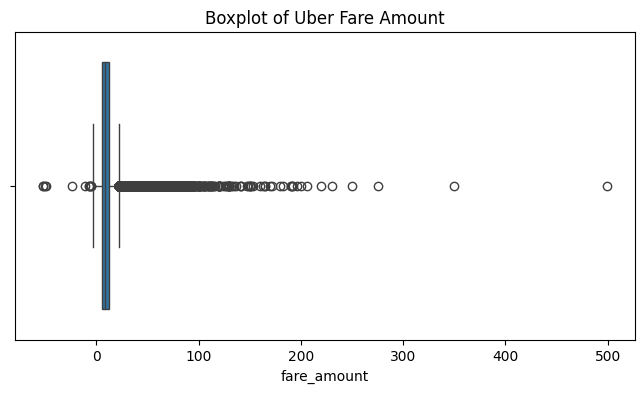

In [7]:
plt.figure(figsize=(8, 4))
sns.boxplot(x=df['fare_amount'])

plt.title("Boxplot of Uber Fare Amount")
plt.show()

In [8]:
Q1 = df['fare_amount'].quantile(0.25)
Q3 = df['fare_amount'].quantile(0.75)

IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

outliers = df[
    (df['fare_amount'] < lower_limit) |
    (df['fare_amount'] > upper_limit)
]

print("Number of outliers:", len(outliers))
print("Lower limit:", lower_limit)
print("Upper limit:", upper_limit)

Number of outliers: 17166
Lower limit: -3.75
Upper limit: 22.25


In [9]:
df = df[
    (df['fare_amount'] > 0) &
    (df['fare_amount'] < 100) &
    (df['passenger_count'] > 0) &
    (df['passenger_count'] <= 6) &
    df['pickup_latitude'].between(40, 42) &
    df['dropoff_latitude'].between(40, 42) &
    df['pickup_longitude'].between(-75, -72) &
    df['dropoff_longitude'].between(-75, -72)
].copy()

print("Shape after cleaning:", df.shape)

Shape after cleaning: (195017, 12)


In [10]:
def haversine(lat1, lon1, lat2, lon2):
    lat1, lon1, lat2, lon2 = map(
        radians, [lat1, lon1, lat2, lon2]
    )

    dlat = lat2 - lat1
    dlon = lon2 - lon1

    a = sin(dlat / 2)**2 + cos(lat1) * cos(lat2) * sin(dlon / 2)**2
    c = 2 * asin(sqrt(a))

    return 6371 * c

In [11]:
df['distance_km'] = df.apply(
    lambda row: haversine(
        row['pickup_latitude'],
        row['pickup_longitude'],
        row['dropoff_latitude'],
        row['dropoff_longitude']
    ),
    axis=1
)

df = df[df['distance_km'] > 0].copy()

print(df[['distance_km', 'fare_amount']].head())

   distance_km  fare_amount
0     1.683323          7.5
1     2.457590          7.7
2     5.036377         12.9
3     1.661683          5.3
4     4.475450         16.0


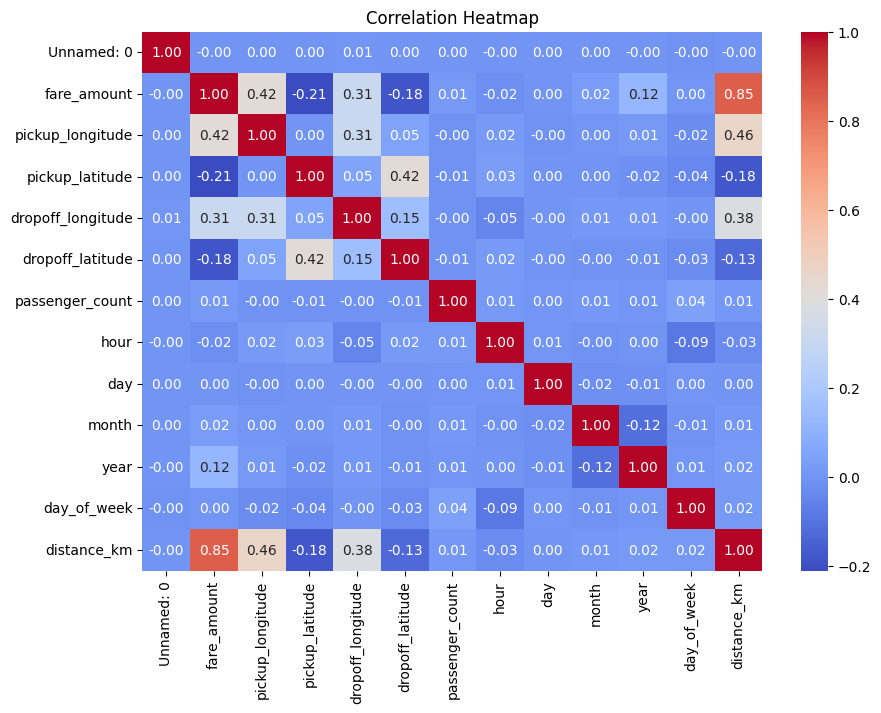

In [12]:
corr = df.select_dtypes(include='number').corr()

plt.figure(figsize=(10, 7))
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.2f')

plt.title("Correlation Heatmap")
plt.show()

In [13]:
features = [
    'distance_km',
    'hour',
    'day',
    'month',
    'year',
    'day_of_week',
    'passenger_count'
]

X = df[features]
y = df['fare_amount']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training records:", X_train.shape[0])
print("Testing records:", X_test.shape[0])

Training records: 154389
Testing records: 38598


In [14]:
lr_model = LinearRegression()

lr_model.fit(X_train, y_train)

y_pred_lr = lr_model.predict(X_test)

print("Linear Regression completed.")

Linear Regression completed.


In [15]:
rf_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)

y_pred_rf = rf_model.predict(X_test)

print("Random Forest Regression completed.")

Random Forest Regression completed.


In [16]:
def evaluate_model(y_true, y_pred, model_name):
    r2 = r2_score(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    mae = mean_absolute_error(y_true, y_pred)

    print("\n", model_name)
    print("R2 Score:", round(r2, 4))
    print("RMSE:", round(rmse, 4))
    print("MAE:", round(mae, 4))

    return r2, rmse, mae

In [17]:
lr_scores = evaluate_model(
    y_test, y_pred_lr, "Linear Regression"
)


 Linear Regression
R2 Score: 0.7631
RMSE: 4.5434
MAE: 2.3087


In [18]:
rf_scores = evaluate_model(
    y_test, y_pred_rf, "Random Forest Regression"
)


 Random Forest Regression
R2 Score: 0.8198
RMSE: 3.9631
MAE: 2.108


In [19]:
results = pd.DataFrame({
    'Model': ['Linear Regression', 'Random Forest Regression'],
    'R2 Score': [lr_scores[0], rf_scores[0]],
    'RMSE': [lr_scores[1], rf_scores[1]],
    'MAE': [lr_scores[2], rf_scores[2]]
})

print(results)

                      Model  R2 Score      RMSE       MAE
0         Linear Regression  0.763146  4.543379  2.308678
1  Random Forest Regression  0.819786  3.963084  2.107979


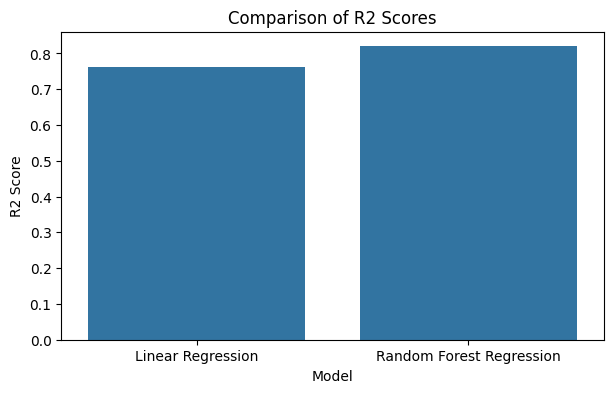

In [20]:
plt.figure(figsize=(7, 4))

sns.barplot(data=results, x='Model', y='R2 Score')

plt.title("Comparison of R2 Scores")
plt.ylabel("R2 Score")
plt.show()